# South German Credit — Exploratory Data Analysis (Milestone 1)

This notebook inspects, validates and describes the **UCI South German Credit** dataset (1,000 credits, 1973–1975).
No models are trained here.

**Scope and caveats, up front**

* Bad credits were **deliberately oversampled**. The sample's 30% bad-credit frequency is a property of the sampling design,
  **not** a real-world default probability. All rates below are only meaningful as *comparisons between groups within this sample*.
* Associations shown here are **not causal**.
* The data are ~50 years old and are **not representative of modern borrowers**. Nothing in this notebook is suitable for real lending decisions.

See `data/README.md` for source, license, citation and the full code table.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = Path("../data/credit_data.csv")
EXPECTED_CSV_SHA256 = "a4e28e9ca9e250ca619b052f73bf63c1f4ab9c8e883a2b944f68251ed55a02f3"

## 1. Load the data and verify file integrity

The CSV is a lossless re-export of `SouthGermanCredit.asc` from the official UCI archive, with German column names replaced by
the English names used in the official R reader (`read_SouthGermanCredit.R`). All values are the original integer codes.

In [2]:
csv_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert csv_sha256 == EXPECTED_CSV_SHA256, f"CSV hash mismatch: {csv_sha256}"

df = pd.read_csv(DATA_PATH)
print(f"SHA-256 OK: {csv_sha256}")
print(f"Shape: {df.shape}")
df.head()

SHA-256 OK: a4e28e9ca9e250ca619b052f73bf63c1f4ab9c8e883a2b944f68251ed55a02f3
Shape: (1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,4,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,2,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,4,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,2,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,4,2,38,1,2,2,2,2,1,1,1


## 2. Schema and feature types

The file stores everything as integers, but only three columns are genuinely quantitative. The others are **integer codes for categories**,
and arithmetic on them (e.g. a mean of `purpose`) is meaningless.

The codes are Häußler's "P2" scores, which come from **experienced credit officers' prior judgement** that a larger code indicates a better credit risk.
This explains reversed-looking scales: for example, `installment_rate = 1` is the *highest* burden (≥ 35% of disposable income).
The code order is an expert opinion, **not an empirical ranking**. In this sample, the highest code has the *highest* bad-risk rate for
`installment_rate`, `property` and `housing` (see section 7). The codes are therefore treated as labels, not as measured risk levels.

In [3]:
NUMERIC = ["duration", "amount", "age"]
ORDINAL = ["employment_duration", "installment_rate", "present_residence", "property", "number_credits", "job", "savings"]
NOMINAL = ["status", "credit_history", "purpose", "personal_status_sex", "other_debtors", "other_installment_plans", "housing"]
BINARY = ["people_liable", "telephone", "foreign_worker"]
TARGET = "credit_risk"
CATEGORICAL = ORDINAL + NOMINAL + BINARY

expected_columns = [
    "status", "duration", "credit_history", "purpose", "amount", "savings", "employment_duration",
    "installment_rate", "personal_status_sex", "other_debtors", "present_residence", "property", "age",
    "other_installment_plans", "housing", "number_credits", "job", "people_liable", "telephone",
    "foreign_worker", "credit_risk",
]
assert list(df.columns) == expected_columns
assert sorted(NUMERIC + CATEGORICAL + [TARGET]) == sorted(expected_columns)  # every column typed exactly once
assert df.shape == (1000, 21)
assert (df.dtypes == "int64").all()

schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "role": ["target" if c == TARGET else "numeric" if c in NUMERIC else "ordinal" if c in ORDINAL
             else "nominal" if c in NOMINAL else "binary" for c in df.columns],
    "n_unique": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
schema

,dtype,role,n_unique,min,max
status,int64,nominal,4,1,4
duration,int64,numeric,33,4,72
credit_history,int64,nominal,5,0,4
purpose,int64,nominal,10,0,10
amount,int64,numeric,923,250,18424
savings,int64,ordinal,5,1,5
employment_duration,int64,ordinal,5,1,5
installment_rate,int64,ordinal,4,1,4
personal_status_sex,int64,nominal,4,1,4
other_debtors,int64,nominal,3,1,3


## 3. Validate category codes against the official code table

The mapping below is transcribed from `codetable.txt` in the UCI archive. Every observed value must belong to the allowed code set.

In [4]:
CODES = {
    "status": {1: "no checking account", 2: "< 0 DM", 3: "0 <= ... < 200 DM", 4: ">= 200 DM / salary >= 1 yr"},
    "credit_history": {0: "delay in paying off in the past", 1: "critical account/other credits elsewhere",
                       2: "no credits taken/all paid back duly", 3: "existing credits paid back duly till now",
                       4: "all credits at this bank paid back duly"},
    "purpose": {0: "others", 1: "car (new)", 2: "car (used)", 3: "furniture/equipment", 4: "radio/television",
                5: "domestic appliances", 6: "repairs", 7: "education", 8: "vacation", 9: "retraining", 10: "business"},
    "savings": {1: "unknown/no savings account", 2: "< 100 DM", 3: "100 <= ... < 500 DM", 4: "500 <= ... < 1000 DM", 5: ">= 1000 DM"},
    "employment_duration": {1: "unemployed", 2: "< 1 yr", 3: "1 <= ... < 4 yrs", 4: "4 <= ... < 7 yrs", 5: ">= 7 yrs"},
    "installment_rate": {1: ">= 35%", 2: "25 <= ... < 35%", 3: "20 <= ... < 25%", 4: "< 20%"},
    "personal_status_sex": {1: "male: divorced/separated", 2: "female: non-single OR male: single",
                            3: "male: married/widowed", 4: "female: single"},
    "other_debtors": {1: "none", 2: "co-applicant", 3: "guarantor"},
    "present_residence": {1: "< 1 yr", 2: "1 <= ... < 4 yrs", 3: "4 <= ... < 7 yrs", 4: ">= 7 yrs"},
    "property": {1: "unknown / no property", 2: "car or other", 3: "building soc. savings / life insurance", 4: "real estate"},
    "other_installment_plans": {1: "bank", 2: "stores", 3: "none"},
    "housing": {1: "for free", 2: "rent", 3: "own"},
    "number_credits": {1: "1", 2: "2-3", 3: "4-5", 4: ">= 6"},
    "job": {1: "unemployed/unskilled - non-resident", 2: "unskilled - resident", 3: "skilled employee/official",
            4: "manager/self-employed/highly qualified"},
    "people_liable": {1: "3 or more", 2: "0 to 2"},
    "telephone": {1: "no", 2: "yes (under customer name)"},
    "foreign_worker": {1: "yes", 2: "no"},
    "credit_risk": {0: "bad", 1: "good"},
}
assert set(CODES) == set(CATEGORICAL + [TARGET])

code_check = pd.DataFrame({
    "allowed": [sorted(CODES[c]) for c in CODES],
    "observed": [sorted(df[c].unique()) for c in CODES],
    "invalid_values": [int((~df[c].isin(CODES[c].keys())).sum()) for c in CODES],
    "unused_codes": [sorted(set(CODES[c]) - set(df[c].unique())) for c in CODES],
}, index=list(CODES))
assert code_check["invalid_values"].sum() == 0
code_check

,allowed,observed,invalid_values,unused_codes
status,"[1, 2, 3, 4]","[1, 2, 3, 4]",0,[]
credit_history,"[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]",0,[]
purpose,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[0, 1, 2, 3, 4, 5, 6, 8, 9, 10]",0,[7]
savings,"[1, 2, 3, 4, 5]","[1, 2, 3, 4, 5]",0,[]
employment_duration,"[1, 2, 3, 4, 5]","[1, 2, 3, 4, 5]",0,[]
installment_rate,"[1, 2, 3, 4]","[1, 2, 3, 4]",0,[]
personal_status_sex,"[1, 2, 3, 4]","[1, 2, 3, 4]",0,[]
other_debtors,"[1, 2, 3]","[1, 2, 3]",0,[]
present_residence,"[1, 2, 3, 4]","[1, 2, 3, 4]",0,[]
property,"[1, 2, 3, 4]","[1, 2, 3, 4]",0,[]


All values are valid. One allowed code never occurs: **`purpose = 7` (education) has zero observations**. The official R reader explicitly keeps it as an empty level.

**Label provenance.** Every code→label pair was cross-checked against the original German code book (Open Data LMU, after Fahrmeir/Hamerle) and Table 1 of Grömping (2019).
Taking `credit_risk = 0` as bad, the per-class percentages computed from this file reproduce all 69 published category rows (see `data/README.md`).
In particular, `housing` is 1 = rent-free, 2 = rent, 3 = own (*Eigentumswohnung*, an owner-occupied flat). This **differs from the older Statlog German Credit documentation**,
which Grömping identifies as having mixed-up housing levels.

Numeric columns have plausible ranges (checked below). Note that `amount` is documented by UCI as a **monotonic transformation of the original credit amounts**;
the transformation is unknown, so values are treated as an ordered "recorded amount" scale and **not** as true Deutsche Mark figures.

In [5]:
assert df["duration"].between(1, 120).all() and df["age"].between(18, 100).all() and (df["amount"] > 0).all()
df[NUMERIC].agg(["min", "max"])

,duration,amount,age
min,4,250,19
max,72,18424,75


## 4. Target encoding and class balance

In [6]:
assert set(df[TARGET].unique()) == {0, 1}           # 0 = bad, 1 = good (official code table)
df["bad_risk"] = 1 - df[TARGET]                       # derived: 1 = bad credit, used for all rates below
assert (df["bad_risk"] + df[TARGET] == 1).all()

balance = df[TARGET].map(CODES[TARGET]).value_counts().to_frame("n")
balance["share"] = balance["n"] / len(df)
balance

,n,share
credit_risk,,
good,700,0.7
bad,300,0.3


700 good / 300 bad. The 30% bad share was **fixed by the stratified sampling design** (bad credits oversampled), so it is not an estimate of how often borrowers defaulted.

## 5. Missing values and duplicates

In [7]:
missing = df.isna().sum()
n_duplicates = int(df.duplicated().sum())
print(f"Missing values (total): {int(missing.sum())}")
print(f"Columns with any missing values: {list(missing[missing > 0].index)}")
print(f"Exact duplicate rows: {n_duplicates}")

Missing values (total): 0
Columns with any missing values: []
Exact duplicate rows: 0


No missing values (`NaN`) and no exact duplicate rows. There are no sentinel codes for "missing" either; however, some categories
(e.g. `savings = 1` "unknown/no savings account", `property = 1` "unknown / no property") **combine "unknown" with a substantive answer**,
so they cannot be cleanly separated.

## 6. Descriptive statistics for numerical features

Only `duration`, `amount` and `age` are summarised with means/medians/standard deviations.

In [8]:
pd.concat({
    "all": df[NUMERIC].agg(["mean", "median", "std"]).T,
    "good": df.loc[df["bad_risk"] == 0, NUMERIC].agg(["mean", "median", "std"]).T,
    "bad": df.loc[df["bad_risk"] == 1, NUMERIC].agg(["mean", "median", "std"]).T,
}, axis=1).round(1)

all                    good                     bad                
            mean  median     std    mean  median     std    mean  median     std
duration    20.9    18.0    12.1    19.2    18.0    11.1    24.9    24.0    13.3
amount    3271.2  2319.5  2822.8  2985.4  2244.0  2401.5  3938.1  2574.5  3535.8
age         35.5    33.0    11.4    36.2    34.0    11.3    34.0    31.0    11.2

In [9]:
df[NUMERIC + ["bad_risk"]].corr().round(3)

,duration,amount,age,bad_risk
duration,1.000,0.625,-0.038,0.215
amount,0.625,1.000,0.032,0.155
age,-0.038,0.032,1.000,-0.091
bad_risk,0.215,0.155,-0.091,1.000


* Bad credits have **longer durations** (median 24 vs 18 months) and **larger recorded amounts** (median 2,574.5 vs 2,244), and borrowers are slightly **younger** (median 31 vs 34 years).
* `amount` is strongly right-skewed (mean well above median) — medians are the better summary.
* `duration` and `amount` are themselves correlated (r ≈ 0.63), so their individual associations with bad risk overlap and should not be read as independent effects.

## 7. Categorical frequency tables with conditional bad-risk rates

For every integer-coded categorical feature: sample count `n`, share of the sample, and the bad-risk rate within that level.
Rates for small groups (n < 30, flagged) are very imprecise.

In [10]:
freq = pd.concat(
    {c: df.groupby(c)["bad_risk"].agg(n="size", bad_rate="mean") for c in CATEGORICAL},
    names=["feature", "code"],
)
freq.insert(0, "label", [CODES[f][c] for f, c in freq.index])
freq.insert(2, "share", freq["n"] / len(df))
freq["small_n"] = np.where(freq["n"] < 30, "yes", "")
freq

label    n  share  bad_rate small_n
feature                 code                                                                        
employment_duration     1                                   unemployed   62  0.062     0.371        
                        2                                       < 1 yr  172  0.172     0.407        
                        3                             1 <= ... < 4 yrs  339  0.339     0.307        
                        4                             4 <= ... < 7 yrs  174  0.174     0.224        
                        5                                     >= 7 yrs  253  0.253     0.253        
installment_rate        1                                       >= 35%  136  0.136     0.250        
                        2                              25 <= ... < 35%  231  0.231     0.268        
                        3                              20 <= ... < 25%  157  0.157     0.287        
                        4                                        < 20%  476  0.476     0.334        
present_residence       1                                       < 1 yr  130  0.130     0.277        
                        2                             1 <= ... < 4 yrs  308  0.308     0.315        
                        3                             4 <= ... < 7 yrs  149  0.149     0.289        
                        4                                     >= 7 yrs  413  0.413     0.300        
property                1                        unknown / no property  282  0.282     0.213        
                        2                                 car or other  232  0.232     0.306        
                        3       building soc. savings / life insurance  332  0.332     0.307        
                        4                                  real estate  154  0.154     0.435        
number_credits          1                                            1  633  0.633     0.316        
                        2                                          2-3  333  0.333     0.276        
                        3                                          4-5   28  0.028     0.214     yes
                        4                                         >= 6    6  0.006     0.333     yes
job                     1          unemployed/unskilled - non-resident   22  0.022     0.318     yes
                        2                         unskilled - resident  200  0.200     0.280        
                        3                    skilled employee/official  630  0.630     0.295        
                        4       manager/self-employed/highly qualified  148  0.148     0.345        
savings                 1                   unknown/no savings account  603  0.603     0.360        
                        2                                     < 100 DM  103  0.103     0.330        
                        3                          100 <= ... < 500 DM   63  0.063     0.175        
                        4                         500 <= ... < 1000 DM   48  0.048     0.125        
                        5                                   >= 1000 DM  183  0.183     0.175        
status                  1                          no checking account  274  0.274     0.493        
                        2                                       < 0 DM  269  0.269     0.390        
                        3                            0 <= ... < 200 DM   63  0.063     0.222        
                        4                   >= 200 DM / salary >= 1 yr  394  0.394     0.117        
credit_history          0              delay in paying off in the past   40  0.040     0.625        
                        1     critical account/other credits elsewhere   49  0.049     0.571        
                        2          no credits taken/all paid back duly  530  0.530     0.319        
                        3     existing credits paid back duly till now   88  0.088     0.318        
                        4

**Bad-risk rates for numerical features in bands**, with an approximate 95% interval (normal approximation, p ± 1.96·√(p(1−p)/n))
to make the sampling uncertainty explicit.

In [11]:
df["duration_band"] = pd.cut(df["duration"], bins=[0, 12, 24, 36, 72], labels=["<= 12", "13-24", "25-36", "37-72"])
df["age_band"] = pd.cut(df["age"], bins=[18, 25, 35, 50, 75], labels=["19-25", "26-35", "36-50", "51-75"])

banded = pd.concat({
    b: df.groupby(b, observed=True)["bad_risk"].agg(n="size", bad_rate="mean") for b in ["duration_band", "age_band"]
}, names=["band", "level"])
half_width = 1.96 * np.sqrt(banded["bad_rate"] * (1 - banded["bad_rate"]) / banded["n"])
banded["ci95_low"] = banded["bad_rate"] - half_width
banded["ci95_high"] = banded["bad_rate"] + half_width
banded

n  bad_rate  ci95_low  ci95_high
band          level                                    
duration_band <= 12  359     0.212     0.169      0.254
              13-24  411     0.297     0.253      0.341
              25-36  143     0.399     0.318      0.479
              37-72   87     0.517     0.412      0.622
age_band      19-25  190     0.421     0.351      0.491
              26-35  397     0.297     0.252      0.342
              36-50  300     0.237     0.189      0.285
              51-75  113     0.274     0.192      0.357

## 8. Visualisations

Exactly three plots. Error bars are approximate 95% intervals; the dashed line is the sample-wide bad share (30%), shown only as a within-sample reference.

### Plot 1 — Bad-risk rate by checking-account status

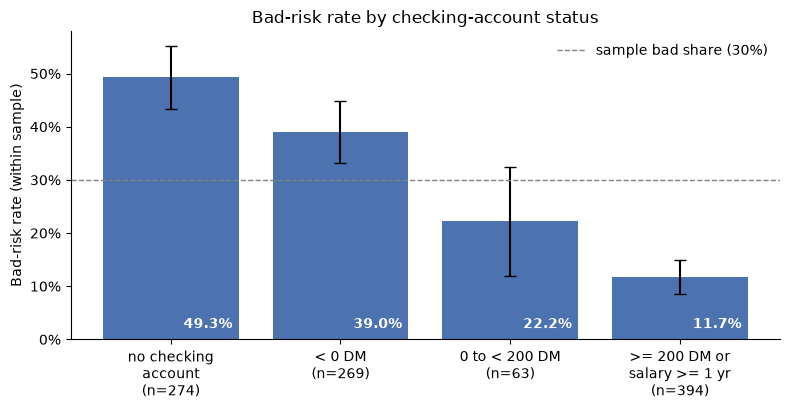

,n,bad_rate,label
status,,,
1,274,0.493,no checking account
2,269,0.390,< 0 DM
3,63,0.222,0 <= ... < 200 DM
4,394,0.117,>= 200 DM / salary >= 1 yr


In [12]:
status = df.groupby("status")["bad_risk"].agg(n="size", bad_rate="mean")
status_err = 1.96 * np.sqrt(status["bad_rate"] * (1 - status["bad_rate"]) / status["n"])
short_status = {1: "no checking\naccount", 2: "< 0 DM", 3: "0 to < 200 DM", 4: ">= 200 DM or\nsalary >= 1 yr"}
status_labels = [f"{short_status[c]}\n(n={n})" for c, n in status["n"].items()]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(status_labels, status["bad_rate"], yerr=status_err, capsize=4, color="#4C72B0")
ax.axhline(df["bad_risk"].mean(), ls="--", color="grey", lw=1, label="sample bad share (30%)")
for i, r in enumerate(status["bad_rate"]):
    ax.text(i + 0.22, 0.015, f"{r:.1%}", ha="center", va="bottom", color="white", fontweight="bold")
ax.set_ylabel("Bad-risk rate (within sample)")
ax.set_title("Bad-risk rate by checking-account status")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
status.assign(label=[CODES["status"][c] for c in status.index])

**Interpretation.** Checking-account status shows the largest spread of any single feature in this sample: from **49.3%** bad (no checking account, n=274) and
**39.0%** (balance < 0 DM, n=269) down to **22.2%** (0–200 DM, n=63) and **11.7%** (≥ 200 DM or salary account, n=394).
The 0–200 DM group is small, so its interval is wide. Status is plausibly a proxy for overall financial position rather than a cause of default.

### Plot 2 — Bad-risk rate by credit duration band

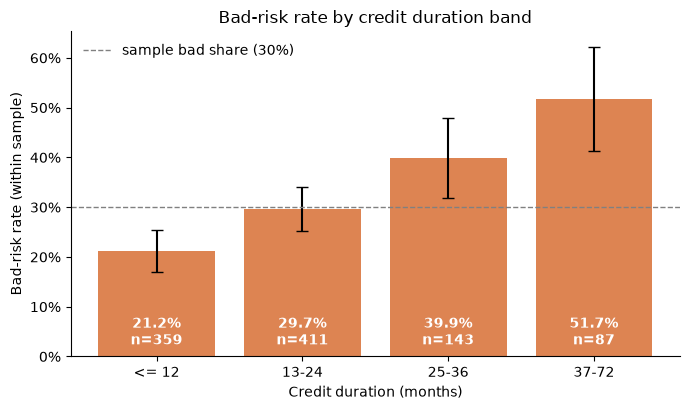

,n,bad_rate
duration_band,,
<= 12,359,0.212
13-24,411,0.297
25-36,143,0.399
37-72,87,0.517


In [13]:
dur = df.groupby("duration_band", observed=True)["bad_risk"].agg(n="size", bad_rate="mean")
dur_err = 1.96 * np.sqrt(dur["bad_rate"] * (1 - dur["bad_rate"]) / dur["n"])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(dur.index.astype(str), dur["bad_rate"], yerr=dur_err, capsize=4, color="#DD8452")
ax.axhline(df["bad_risk"].mean(), ls="--", color="grey", lw=1, label="sample bad share (30%)")
for i, (n, r) in enumerate(zip(dur["n"], dur["bad_rate"])):
    ax.text(i, 0.015, f"{r:.1%}\nn={n}", ha="center", va="bottom", color="white", fontweight="bold")
ax.set_xlabel("Credit duration (months)")
ax.set_ylabel("Bad-risk rate (within sample)")
ax.set_title("Bad-risk rate by credit duration band")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
dur

**Interpretation.** The bad-risk rate rises steadily with duration: **21.2%** (≤ 12 months, n=359), **29.7%** (13–24, n=411), **39.9%** (25–36, n=143)
and **51.7%** (37–72, n=87). The gradient is monotonic, but the two longest bands are smaller and less precise.
Longer credits are also larger (r ≈ 0.63 with amount) and may be granted to different kinds of borrowers, so duration alone does not explain the pattern.

### Plot 3 — Recorded credit amount distribution by risk class

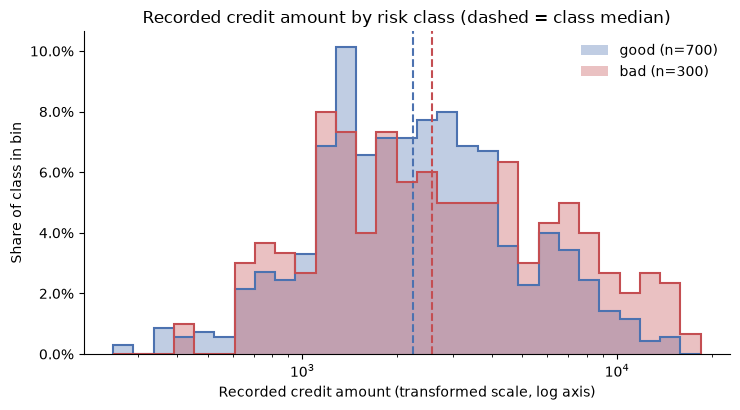

,count,mean,std,min,25%,50%,75%,90%,max
bad_risk,,,,,,,,,
bad,300.0,3938.1,3535.8,433.0,1352.5,2574.5,5141.5,8983.6,18424.0
good,700.0,2985.4,2401.5,250.0,1375.5,2244.0,3634.8,6318.7,15857.0


In [14]:
log_bins = np.logspace(np.log10(df["amount"].min()), np.log10(df["amount"].max()), 30)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for value, name, color in [(0, "good", "#4C72B0"), (1, "bad", "#C44E52")]:
    amounts = df.loc[df["bad_risk"] == value, "amount"]
    ax.hist(amounts, bins=log_bins, weights=np.full(len(amounts), 1 / len(amounts)),
            histtype="stepfilled", alpha=0.35, color=color, label=f"{name} (n={len(amounts)})")
    ax.hist(amounts, bins=log_bins, weights=np.full(len(amounts), 1 / len(amounts)), histtype="step", lw=1.5, color=color)
    ax.axvline(amounts.median(), color=color, lw=1.5, ls="--")
ax.set_xscale("log")
ax.set_xlabel("Recorded credit amount (transformed scale, log axis)")
ax.set_ylabel("Share of class in bin")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Recorded credit amount by risk class (dashed = class median)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
df.groupby(df["bad_risk"].map({0: "good", 1: "bad"}))["amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1)

**Interpretation.** Each class is normalised to sum to 100% because the classes differ in size (700 vs 300). The two distributions overlap heavily; the bad class is shifted modestly
towards larger amounts (median **2,574.5** vs **2,244**) and has a much heavier upper tail (mean 3,938 vs 2,985; 90th percentile 8,984 vs 6,319).
Because `amount` is a monotonic transformation of unknown form, only the **ordering** of values is reliable — differences should not be read as DM amounts.

## 9. Summary of findings

* **Data quality:** 1,000 rows × 21 columns, all values valid against the official code table, no missing values, no duplicate rows. One code (`purpose = 7`, education) is unused.
* **Strongest single-feature contrasts in this sample:** checking-account status (11.7% → 49.3%), credit history (17.1% for "all credits at this bank paid back duly" vs 62.5% for "delay in paying off in the past", n=40),
  and duration (21.2% → 51.7%). Savings, purpose and age bands show smaller differences.
* **Numerical features:** bad credits are longer and larger on average and borrowers slightly younger, but distributions overlap substantially and duration/amount are correlated.

## 10. Limitations, uncertainty and causation

* **Sampling bias.** Bad credits were oversampled by design. The 30% bad share — and every conditional rate above — is inflated relative to the original portfolio.
  Within-sample *rankings* of groups are informative; absolute levels are not population default probabilities.
* **Selection.** The data include only applicants who **were granted** credit. Rejected applicants are absent, so relationships may differ in the full applicant population.
* **Uncertainty.** With 1,000 rows, many subgroup counts are small (some purposes have n ≤ 22). Intervals shown are rough normal approximations; no multiple-comparison adjustment was made
  across the many tables, so some apparent differences will be noise.
* **Correlation ≠ causation.** These are observational associations. Features are interrelated (e.g. duration and amount), confounded by unobserved factors (income, the bank's own approval rules),
  and some may reflect how the bank *chose* terms for different customers. None of the patterns shows that changing a feature would change default risk.
* **Data coding limits.** `amount` is transformed with unknown form; original `number_credits` values are unavailable; sex cannot be recovered from `personal_status_sex` (code 2 mixes
  female non-single and male single); "unknown" is merged with substantive answers in `savings` and `property`.
* **Historical context.** Data from 1973–1975 in (West) Germany. Products, regulations and borrower behaviour have changed (e.g. `telephone` is obsolete as a signal); results do not generalise to modern borrowers.
* **Fairness.** `personal_status_sex`, `age` and `foreign_worker` are sensitive attributes; using them in real lending would raise legal and ethical concerns.
* **Not for decisions.** This analysis is educational and must not be used for actual lending decisions.